<a href="https://colab.research.google.com/github/rybak97/free_courses/blob/main/Artificial_Immune_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on: https://www.datacamp.com/tutorial/artificial-immune-system

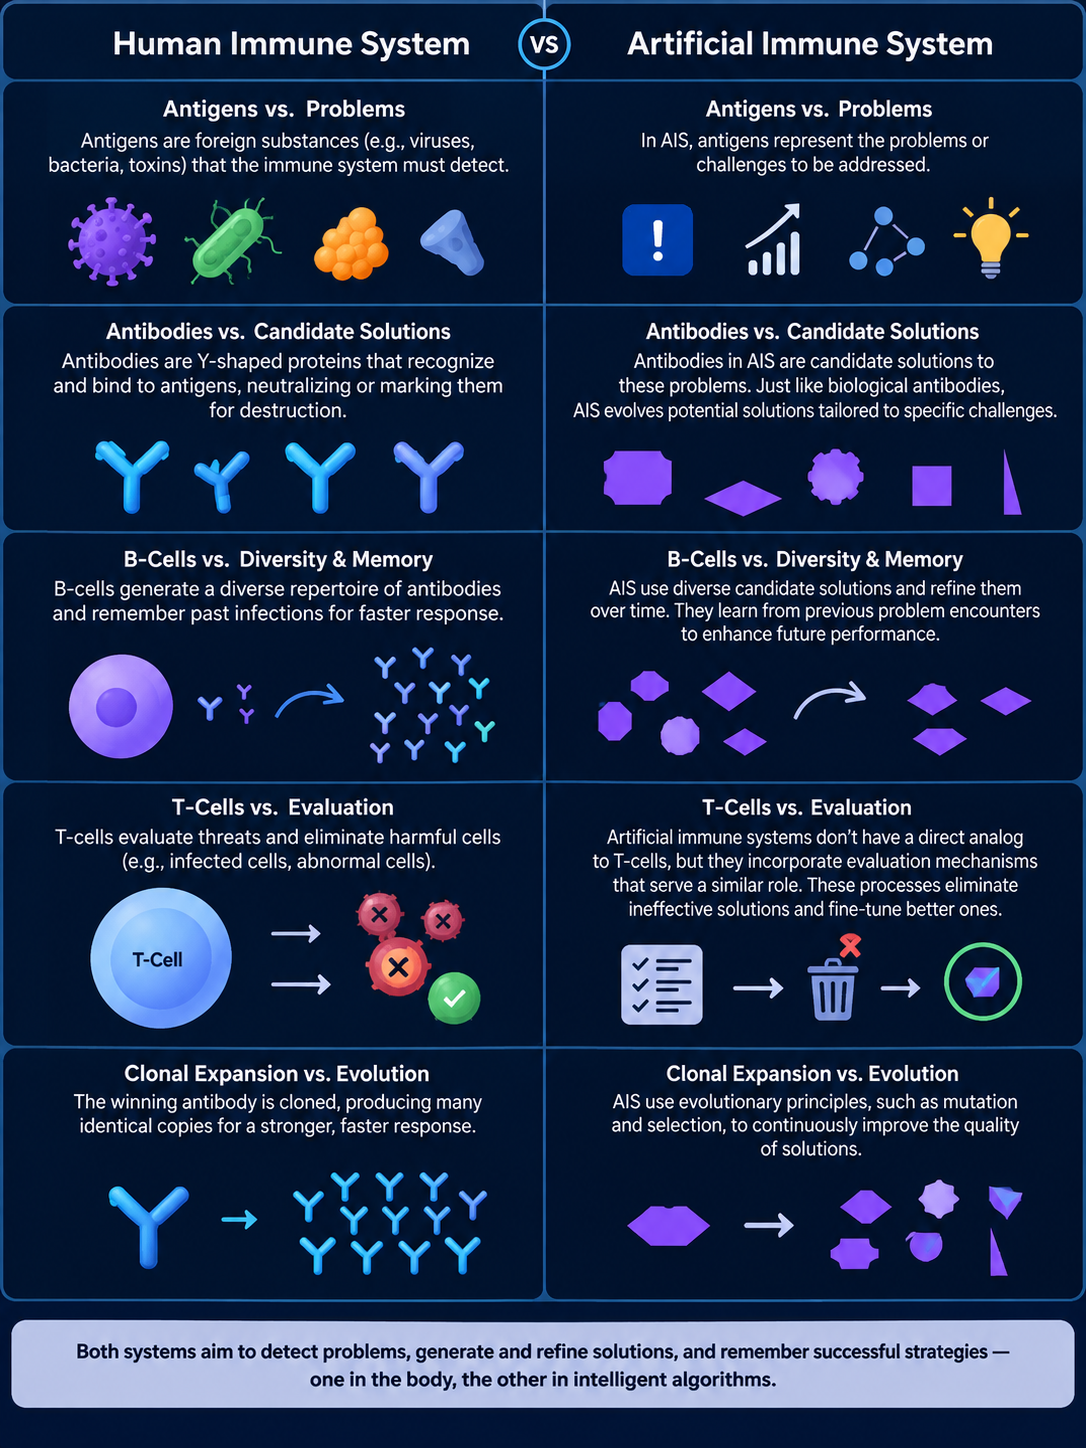

1. Clonal Selection Algorithm (CSA)

The clonal selection algorithm (CSA) is inspired by how B-cells respond to antigens. When the immune system detects a threat, it selects the antibodies that recognize it most effectively.

These cells are cloned, and their copies undergo mutations to create improved variations. The best-performing solutions are then selected and stored in memory.

Similarly, CSA uses selection, cloning and mutation to gradually improve candidate solutions. It is mainly used in optimization problems, such as engineering design and resource allocation.

2. Negative Selection Algorithm (NSA)

The negative selection algorithm (NSA) is inspired by how T-cells develop in the human immune system. During their maturation, T-cells that recognize the body's own cells are eliminated, preventing them from attacking healthy tissue.

Similarly, NSA learns to distinguish between normal and abnormal patterns. It generates detectors and removes those that match known normal patterns (self). The remaining detectors can identify unusual or potentially harmful patterns (non-self).

NSA is mainly used for anomaly detection and cybersecurity, for example, identifying suspicious network activity or unauthorized access.

3. Immune Network Theory (INT)

Immune Network Theory (INT) is inspired by interactions between antibodies and other immune cells. Instead of working independently, immune components communicate with and influence one another through stimulation and suppression.

Similarly, INT algorithms create networks of interconnected candidate solutions. These solutions interact based on their similarity, helping maintain diversity and eliminate redundant elements.

INT is commonly used in pattern recognition, data clustering and classification, where relationships between different patterns are important.

# CSA in optimize Rastrigin function

### 1. Imports and Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

### 2. Objective Function and CSA Components

In [ ]:
# Define the Rastrigin function
def rastrigin(X):
    n = len(X)
    return 10 * n + np.sum(X**2 - 10 * np.cos(2 * np.pi * X))

# Generate the initial population of potential solutions
def generate_initial_population(pop_size, solution_size):
    return np.random.uniform(-5.12, 5.12, size=(pop_size, solution_size))

# Evaluate the fitness of each individual (lower is better)
def evaluate_population(population):
    return np.array([rastrigin(individual) for individual in population])

# Select the best candidates based on fitness
def select_best_candidates(population, fitness, num_candidates):
    indices = np.argsort(fitness)
    return population[indices[:num_candidates]], fitness[indices[:num_candidates]]

# Clone the best candidates
def clone_candidates(candidates, num_clones):
    return np.repeat(candidates, num_clones, axis=0)

# Introduce random mutations
def mutate_clones(clones, mutation_rate):
    mutations = np.random.rand(*clones.shape) < mutation_rate
    clones[mutations] += np.random.uniform(-1, 1, np.sum(mutations))
    return clones

### 3. Clonal Selection Algorithm Execution

In [ ]:
def clonal_selection_algorithm(solution_size=2, pop_size=100, num_candidates=10, num_clones=10, mutation_rate=0.05, generations=100):
    population = generate_initial_population(pop_size, solution_size)
    best_fitness_per_generation = []

    for generation in range(generations):
        fitness = evaluate_population(population)
        candidates, candidate_fitness = select_best_candidates(population, fitness, num_candidates)
        clones = clone_candidates(candidates, num_clones)
        mutated_clones = mutate_clones(clones, mutation_rate)
        clone_fitness = evaluate_population(mutated_clones)

        # Replace
        population[:len(mutated_clones)] = mutated_clones
        fitness[:len(clone_fitness)] = clone_fitness

        # Track best
        best_fitness = np.min(fitness)
        best_fitness_per_generation.append(best_fitness)

        if best_fitness < 1e-6:
            print(f"Optimal solution found in {generation + 1} generations.")
            break

    best_solution = population[np.argmin(fitness)]
    return best_solution, best_fitness_per_generation

# Execute CSA
best_solution, fitness_history = clonal_selection_algorithm(solution_size=2)
print("Best solution found:", best_solution)
print("Rastrigin function value at best solution:", rastrigin(best_solution))

Best solution found: [0.00182217 0.00218679]
Rastrigin function value at best solution: 0.0016074193209050236


### 4. Visualizations
Below we plot the fitness improvement history using a logarithmic scale on the Y-axis so that minor optimizations in the final generations are highly visible. We also construct a 3D visualization alongside the 2D contour.

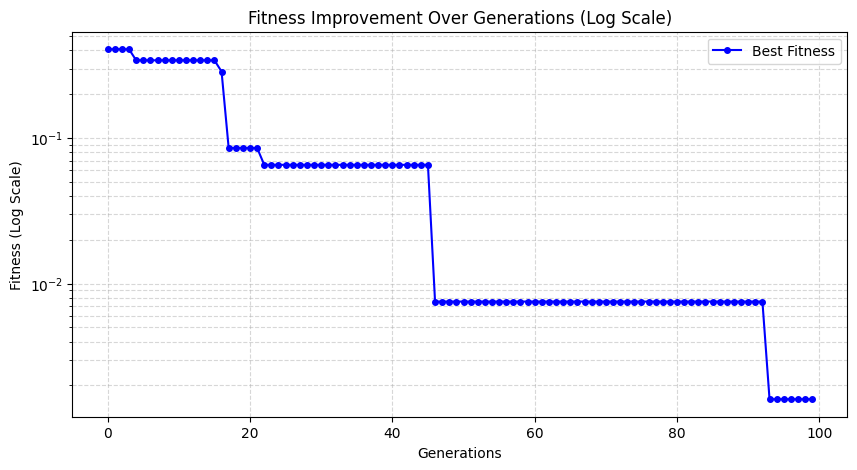

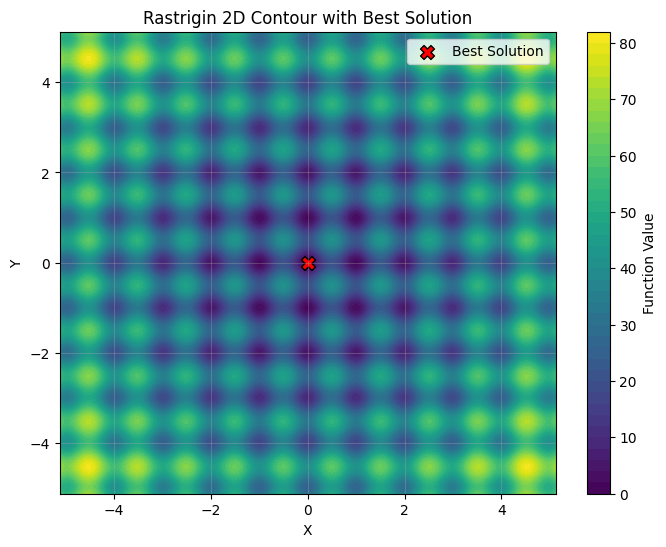

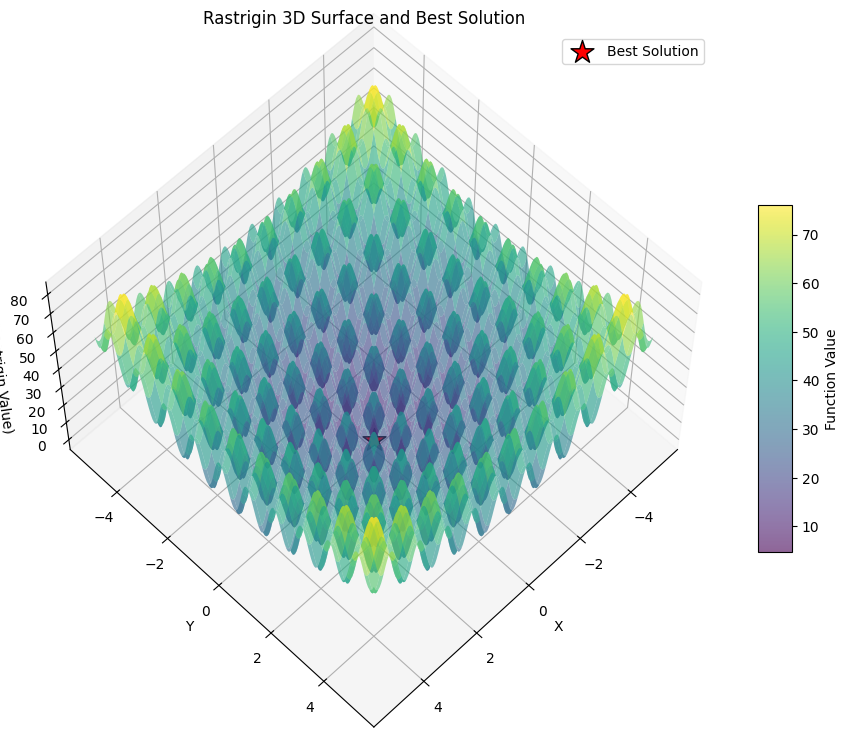

In [ ]:
# 1. Improved Fitness Trend Plot (using Log Scale to see later generation details)
plt.figure(figsize=(10, 5))
plt.plot(fitness_history, marker='o', markersize=4, color='blue', label='Best Fitness')
plt.yscale('log')  # Logarithmic scale makes the small changes visible
plt.xlabel('Generations')
plt.ylabel('Fitness (Log Scale)')
plt.title('Fitness Improvement Over Generations (Log Scale)')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Set up meshgrid for plotting
x = np.linspace(-5.12, 5.12, 200)
y = np.linspace(-5.12, 5.12, 200)
X, Y = np.meshgrid(x, y)
Z = 10 * 2 + (X**2 - 10 * np.cos(2 * np.pi * X)) + (Y**2 - 10 * np.cos(2 * np.pi * Y))

# 2. 2D Contour Plot
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='Function Value')
plt.scatter(best_solution[0], best_solution[1], c='red', s=100, marker='X', label='Best Solution', edgecolor='black')
plt.title('Rastrigin 2D Contour with Best Solution')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. 3D Surface Plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Using alpha=0.6 for surface transparency to allow the point to show through any obscuring peaks
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.6)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Function Value')

# Plot the best solution with a larger, distinctive bright red star
best_z = rastrigin(best_solution)
ax.scatter(best_solution[0], best_solution[1], best_z, color='red', s=300, marker='*', depthshade=False, label='Best Solution', edgecolor='black', zorder=100)

# Set a better viewing angle (elev=35, azim=45 provides an excellent view of the global minimum at the center)
ax.view_init(elev=60, azim=45)

ax.set_title('Rastrigin 3D Surface and Best Solution')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z (Rastrigin Value)')
ax.legend()
plt.show()